# 08 튜터링 발표용 그래프 — 지연 요인 통합 그림

기업 튜터링 최종 발표 슬라이드 6(03 데이터셋 및 EDA ②)에 넣을 그림 한 장을 만든다.
새 분석은 하지 않고, 이미 만든 집계를 발표용으로 다시 그린다.

| 패널 | 출처 | 대상 |
| --- | --- | --- |
| 왼쪽: 거리 구간 × 관내/관외 | `발표자료/중간발표/표/EDA_Q1_거리x관외.csv` (노트북 07) | 안전센터 2024 |
| 오른쪽: 구 신고 집중도 5분위 × 정체 | `work/ref/eda_multivar.parquet` (노트북 05 3절), 구간 나누기는 노트북 05 8절과 같다 | 서울 2024 |

출력: `기업튜터링/발표자료/슬라이드자료/P07_슬6_지연요인_통합.png`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path().resolve()
while not (ROOT / "CLAUDE.md").exists():
    ROOT = ROOT.parent

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

NAVY, ORANGE, GRAY, LIGHT = "#1F3A68", "#C25E17", "#9CA3AF", "#E5E7EB"
OUT = ROOT / "기업튜터링" / "발표자료" / "슬라이드자료" / "P07_슬6_지연요인_통합.png"


In [2]:
dist = pd.read_csv(ROOT / "발표자료" / "중간발표" / "표" / "EDA_Q1_거리x관외.csv", encoding="utf-8-sig")
dist[["관내", "관외"]] = dist[["관내", "관외"]] * 100
print(dist.round(1).to_string(index=False))

m = pd.read_parquet(ROOT / "work" / "ref" / "eda_multivar.parquet")
ok = m["dist_km"].isna() | m["dist_km"].between(0, 100)
dx = m[ok].dropna(subset=["avg_speed_kmh"]).copy()
dx["load_q"] = pd.qcut(dx["sgg_load"], 5, labels=["Q1(한산)", "Q2", "Q3", "Q4", "Q5(혼잡)"])
dx["speed_q"] = pd.qcut(dx["avg_speed_kmh"], 5, labels=["S1(정체)", "S2", "S3", "S4", "S5(원활)"])
cross = dx.pivot_table(index="load_q", columns="speed_q", values="late", aggfunc="mean", observed=True) * 100
print(f"n = {len(dx):,}")
print(cross.round(1).to_string())

dbin   관내   관외
≤1km 23.2 30.9
 1-2 45.3 54.5
 2-3 67.4 76.5
 3-4 84.3 88.3
 4-6 89.9 94.4
>6km 84.7 96.1


n = 548,888
speed_q  S1(정체)    S2    S3    S4  S5(원활)
load_q                                   
Q1(한산)     42.4  41.2  41.7  39.9    42.2
Q2         47.2  45.5  44.8  43.5    43.9
Q3         50.4  49.3  48.4  47.2    45.8
Q4         55.3  54.4  51.7  49.5    47.0
Q5(혼잡)     61.9  60.4  57.0  53.7    49.3


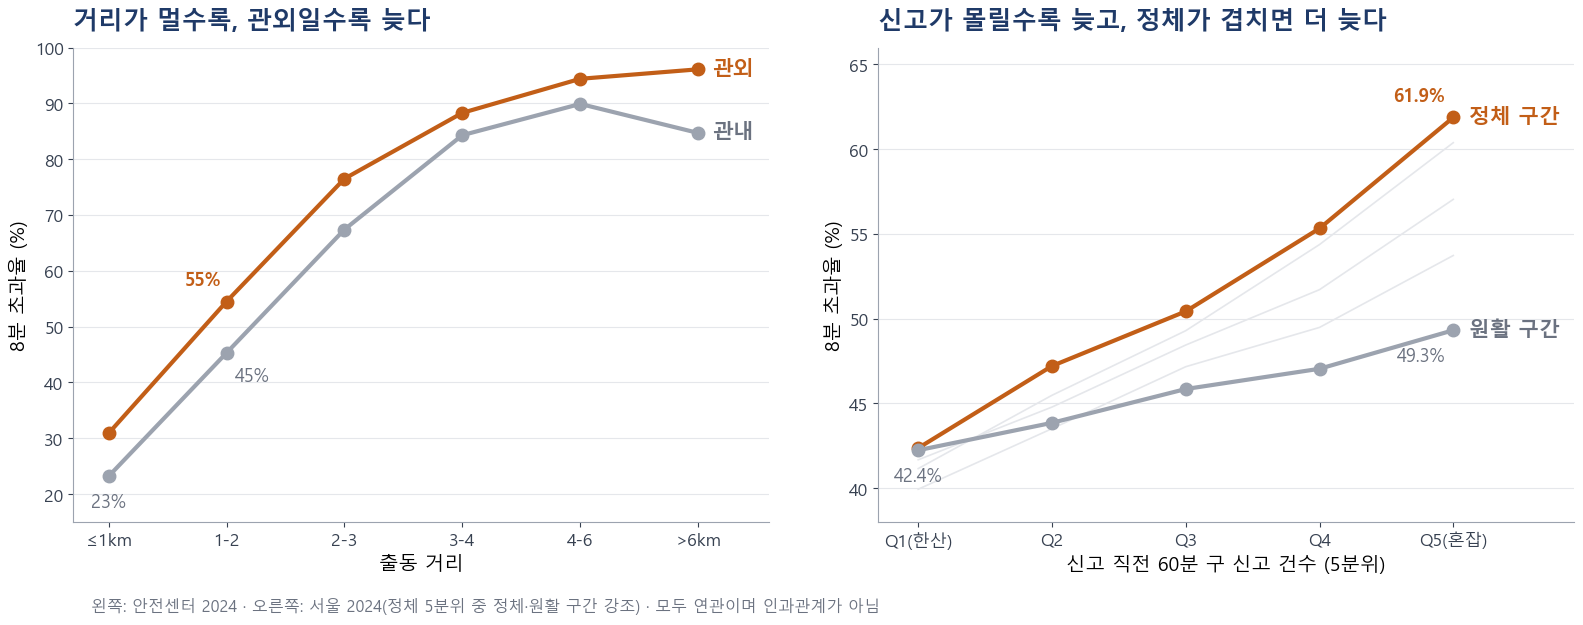

C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project\기업튜터링\발표자료\슬라이드자료\P07_슬6_지연요인_통합.png


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6.2))

x = range(len(dist))
a1.plot(x, dist["관내"], marker="o", lw=3, ms=9, color=GRAY)
a1.plot(x, dist["관외"], marker="o", lw=3, ms=9, color=ORANGE)
a1.set_xticks(list(x), dist["dbin"])
a1.text(len(dist) - 1 + 0.12, dist["관외"].iloc[-1], "관외", color=ORANGE, fontsize=15, fontweight="bold", va="center")
a1.text(len(dist) - 1 + 0.12, dist["관내"].iloc[-1], "관내", color="#6B7280", fontsize=15, fontweight="bold", va="center")
a1.set_xlim(-0.3, len(dist) - 0.4)
a1.set_xlabel("출동 거리", fontsize=14)
a1.set_title("거리가 멀수록, 관외일수록 늦다", fontsize=18, fontweight="bold", color=NAVY, loc="left", pad=14)

xs = range(len(cross))
for col, color, lw in [("S1(정체)", ORANGE, 3), ("S5(원활)", GRAY, 3)]:
    a2.plot(xs, cross[col], marker="o", lw=lw, ms=9, color=color)
for col in ["S2", "S3", "S4"]:
    a2.plot(xs, cross[col], lw=1.2, color=LIGHT, zorder=0)
a2.set_xticks(list(xs), cross.index)
a2.text(len(cross) - 1 + 0.12, cross["S1(정체)"].iloc[-1], "정체 구간", color=ORANGE, fontsize=15, fontweight="bold", va="center")
a2.text(len(cross) - 1 + 0.12, cross["S5(원활)"].iloc[-1], "원활 구간", color="#6B7280", fontsize=15, fontweight="bold", va="center")
a2.set_xlim(-0.3, len(cross) - 0.1)
a2.set_xlabel("신고 직전 60분 구 신고 건수 (5분위)", fontsize=14)
a2.set_title("신고가 몰릴수록 늦고, 정체가 겹치면 더 늦다", fontsize=18, fontweight="bold", color=NAVY, loc="left", pad=14)

for ax, ylim in [(a1, (15, 100)), (a2, (38, 66))]:
    ax.set_ylim(*ylim)
    ax.set_ylabel("8분 초과율 (%)", fontsize=14)
    ax.tick_params(labelsize=12.5, colors="#374151")
    ax.grid(axis="y", color=LIGHT, lw=0.8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRAY)

a1.annotate(f"{dist['관내'].iloc[0]:.0f}%", (0, dist["관내"].iloc[0]), textcoords="offset points", xytext=(0, -22), ha="center", fontsize=13, color="#6B7280")
a1.annotate(f"{dist['관외'].iloc[1]:.0f}%", (1, dist["관외"].iloc[1]), textcoords="offset points", xytext=(-4, 12), ha="right", fontsize=13, color=ORANGE, fontweight="bold")
a1.annotate(f"{dist['관내'].iloc[1]:.0f}%", (1, dist["관내"].iloc[1]), textcoords="offset points", xytext=(6, -20), ha="left", fontsize=13, color="#6B7280")
a2.annotate(f"{cross['S1(정체)'].iloc[0]:.1f}%", (0, cross["S1(정체)"].iloc[0]), textcoords="offset points", xytext=(0, -24), ha="center", fontsize=13, color="#6B7280")
a2.annotate(f"{cross['S1(정체)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S1(정체)"].iloc[-1]), textcoords="offset points", xytext=(-6, 12), ha="right", fontsize=13, color=ORANGE, fontweight="bold")
a2.annotate(f"{cross['S5(원활)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S5(원활)"].iloc[-1]), textcoords="offset points", xytext=(-6, -22), ha="right", fontsize=13, color="#6B7280")

fig.text(0.06, 0.005, "왼쪽: 안전센터 2024 · 오른쪽: 서울 2024(정체 5분위 중 정체·원활 구간 강조) · 모두 연관이며 인과관계가 아님",
         fontsize=11.5, color="#6B7280")
plt.tight_layout(rect=(0, 0.04, 1, 1), w_pad=4)
plt.savefig(OUT, dpi=200, facecolor="white")
plt.show()
print(OUT)

## 슬라이드 칸 맞춤 버전 (4:3, 위아래 배치)

슬라이드 6의 그림 칸이 약 4:3이라 가로형 그림을 넣으면 작아진다. 같은 데이터를 위아래로 쌓고 글자를 키운다.
출력: `기업튜터링/발표자료/슬라이드자료/P07_슬6_지연요인_통합_4x3.png`

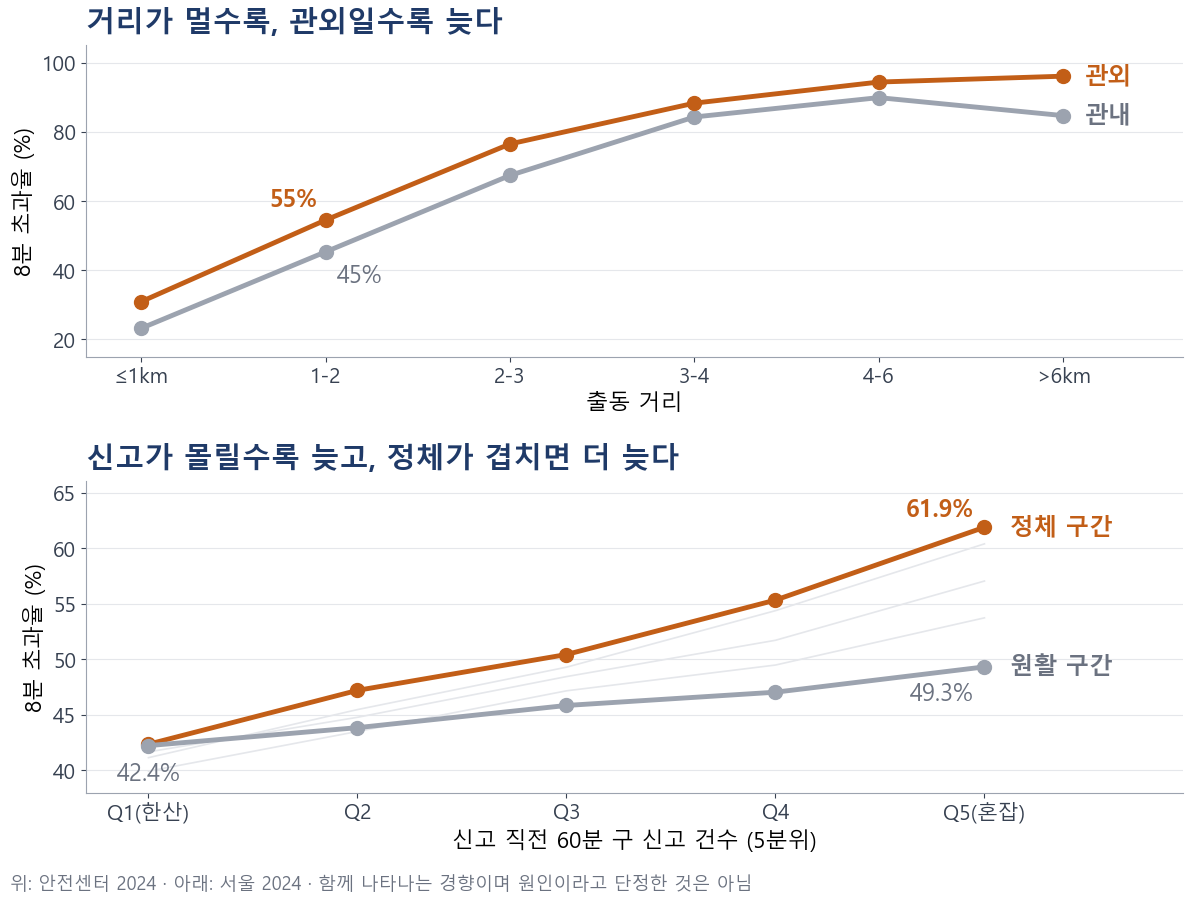

C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project\기업튜터링\발표자료\슬라이드자료\P07_슬6_지연요인_통합_4x3.png


In [4]:
OUT43 = OUT.with_name("P07_슬6_지연요인_통합_4x3.png")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 9))
TS, LS, KS, AS = 21, 16, 15, 17

x = range(len(dist))
a1.plot(x, dist["관내"], marker="o", lw=3.5, ms=10, color=GRAY)
a1.plot(x, dist["관외"], marker="o", lw=3.5, ms=10, color=ORANGE)
a1.set_xticks(list(x), dist["dbin"])
a1.text(len(dist) - 1 + 0.12, dist["관외"].iloc[-1], "관외", color=ORANGE, fontsize=AS, fontweight="bold", va="center")
a1.text(len(dist) - 1 + 0.12, dist["관내"].iloc[-1], "관내", color="#6B7280", fontsize=AS, fontweight="bold", va="center")
a1.set_xlim(-0.3, len(dist) - 0.35)
a1.set_ylim(15, 105)
a1.set_title("거리가 멀수록, 관외일수록 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a1.annotate(f"{dist['관외'].iloc[1]:.0f}%", (1, dist["관외"].iloc[1]), textcoords="offset points", xytext=(-6, 10), ha="right", fontsize=AS, color=ORANGE, fontweight="bold")
a1.annotate(f"{dist['관내'].iloc[1]:.0f}%", (1, dist["관내"].iloc[1]), textcoords="offset points", xytext=(8, -22), ha="left", fontsize=AS, color="#6B7280")

xs = range(len(cross))
for col in ["S2", "S3", "S4"]:
    a2.plot(xs, cross[col], lw=1.2, color=LIGHT, zorder=0)
a2.plot(xs, cross["S1(정체)"], marker="o", lw=3.5, ms=10, color=ORANGE)
a2.plot(xs, cross["S5(원활)"], marker="o", lw=3.5, ms=10, color=GRAY)
a2.set_xticks(list(xs), cross.index)
a2.text(len(cross) - 1 + 0.12, cross["S1(정체)"].iloc[-1], "정체 구간", color=ORANGE, fontsize=AS, fontweight="bold", va="center")
a2.text(len(cross) - 1 + 0.12, cross["S5(원활)"].iloc[-1], "원활 구간", color="#6B7280", fontsize=AS, fontweight="bold", va="center")
a2.set_xlim(-0.3, len(cross) - 0.05)
a2.set_ylim(38, 66)
a2.set_title("신고가 몰릴수록 늦고, 정체가 겹치면 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a2.annotate(f"{cross['S1(정체)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S1(정체)"].iloc[-1]), textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=AS, color=ORANGE, fontweight="bold")
a2.annotate(f"{cross['S5(원활)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S5(원활)"].iloc[-1]), textcoords="offset points", xytext=(-8, -24), ha="right", fontsize=AS, color="#6B7280")
a2.annotate(f"{cross['S1(정체)'].iloc[0]:.1f}%", (0, cross["S1(정체)"].iloc[0]), textcoords="offset points", xytext=(0, -26), ha="center", fontsize=AS, color="#6B7280")

a1.set_xlabel("출동 거리", fontsize=LS)
a2.set_xlabel("신고 직전 60분 구 신고 건수 (5분위)", fontsize=LS)
for ax in (a1, a2):
    ax.set_ylabel("8분 초과율 (%)", fontsize=LS)
    ax.tick_params(labelsize=KS, colors="#374151")
    ax.grid(axis="y", color=LIGHT, lw=0.8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRAY)

fig.text(0.01, 0.005, "위: 안전센터 2024 · 아래: 서울 2024 · 함께 나타나는 경향이며 원인이라고 단정한 것은 아님",
         fontsize=13, color="#6B7280")
plt.tight_layout(rect=(0, 0.03, 1, 1), h_pad=2.2)
plt.savefig(OUT43, dpi=200, facecolor="white")
plt.show()
print(OUT43)

## 박스 대응 4칸 그래프 (4:3)

슬라이드 6의 박스 세 개(① 출동 거리 기본 측정, ② 1차 자문에서 지적받은 관외출동, ③ 추정한 지연 이유 강수·교통)에 한 칸씩 대응한다.

| 칸 | 출처 | 대상 |
| --- | --- | --- |
| ① 거리 | `표/EDA_Q1_거리x시간대.csv` — 시간대 5구간의 최소~최대 범위 | 안전센터 2024 |
| ② 관외출동 | `표/EDA_Q1_거리x관외.csv` | 안전센터 2024 |
| ③ 강수 | `표/EDA_Q3_거리x강수_층화.csv` — 4~10월, 강수 없음 대비 5mm 초과의 차이 | 안전센터 2024 |
| ③ 교통 | 위 `cross` (정체 S1 vs 원활 S5) | 서울 2024 |

출력: `기업튜터링/발표자료/슬라이드자료/P07_슬6_지연요인_4패널.png`

       min   max
dbin            
≤1km  19.0  26.6
1-2   40.8  50.0
2-3   62.2  73.1
3-4   77.9  88.3
4-6   85.1  93.5
>6km  77.2  94.1
  거리  차이(%p)  5mm초과_건수
≤1km   3.207      3800
 1-2   2.663      5403
 2-3   2.509      2620
>3km  -0.231      1118


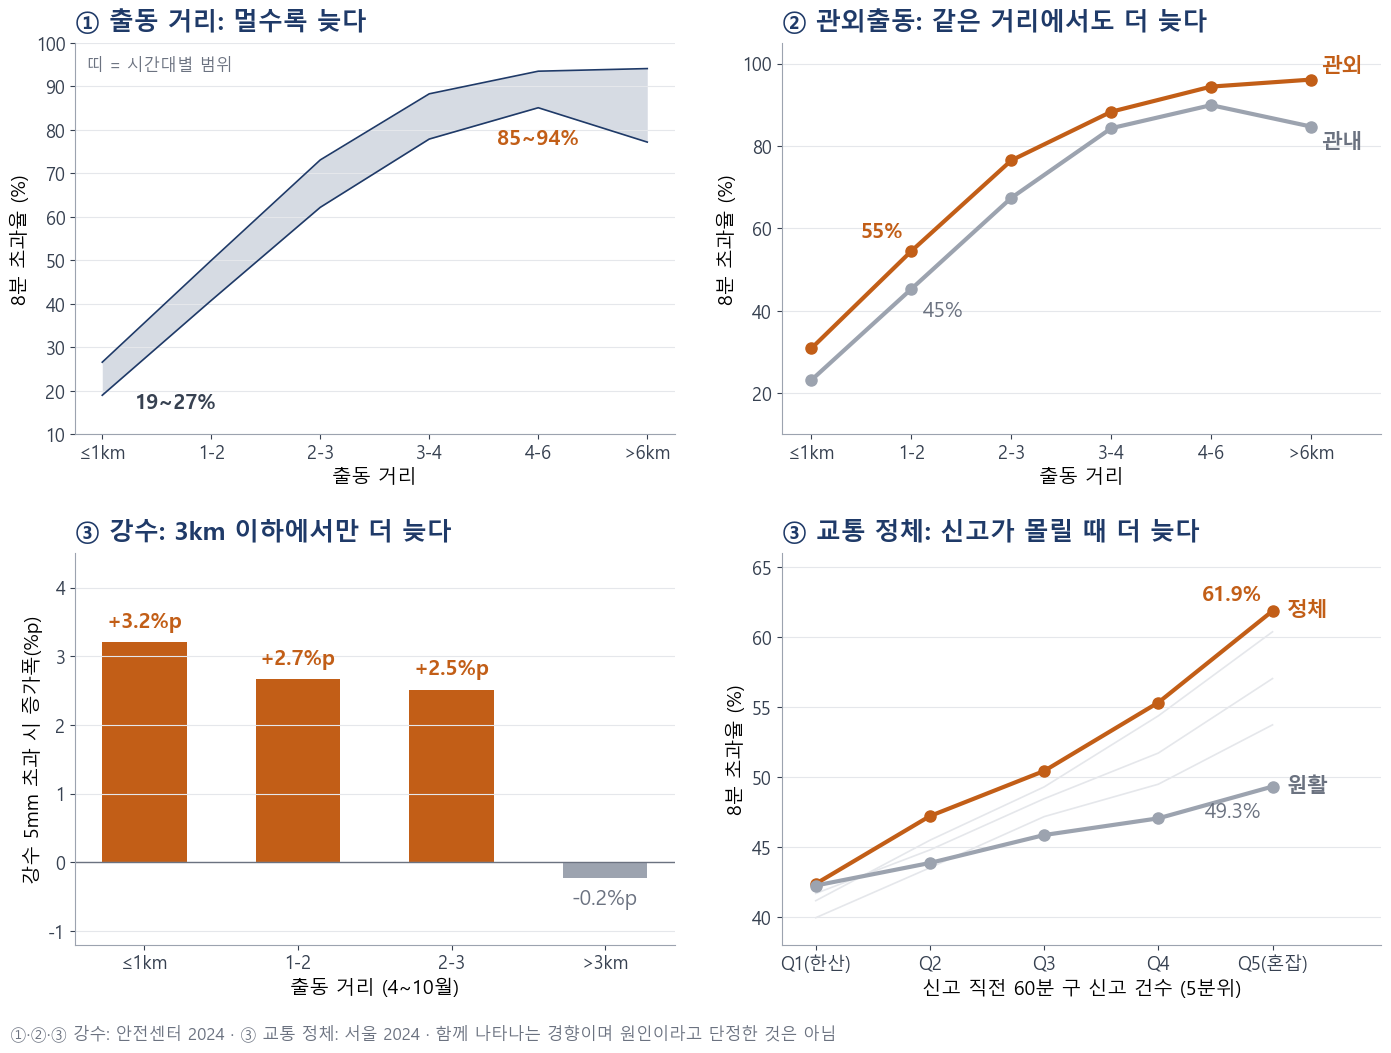

C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project\기업튜터링\발표자료\슬라이드자료\P07_슬6_지연요인_4패널.png


In [5]:
T = ROOT / "발표자료" / "중간발표" / "표"
dt = pd.read_csv(T / "EDA_Q1_거리x시간대.csv", encoding="utf-8-sig").set_index("dbin") * 100
rain = pd.read_csv(T / "EDA_Q3_거리x강수_층화.csv", encoding="utf-8-sig")
rain = rain[rain["계절"] == "4~10월"].reset_index(drop=True)
band_lo, band_hi = dt.min(axis=1), dt.max(axis=1)
print(pd.DataFrame({"min": band_lo, "max": band_hi}).round(1).to_string())
print(rain[["거리", "차이(%p)", "5mm초과_건수"]].to_string(index=False))

OUT4 = OUT.with_name("P07_슬6_지연요인_4패널.png")
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
(a1, a2), (a3, a4) = axs
TS, LS, KS, AS = 18, 14, 13, 15

x = list(range(len(dt)))
a1.fill_between(x, band_lo.values, band_hi.values, color=NAVY, alpha=0.18, lw=0)
a1.plot(x, band_lo.values, color=NAVY, lw=1.2)
a1.plot(x, band_hi.values, color=NAVY, lw=1.2)
a1.set_xticks(x, dt.index)
a1.set_ylim(10, 100)
a1.set_title("① 출동 거리: 멀수록 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a1.text(0.3, 16, f"{band_lo.iloc[0]:.0f}~{band_hi.iloc[0]:.0f}%", fontsize=AS, color="#374151", fontweight="bold")
i46 = list(dt.index).index("4-6")
a1.annotate(f"{band_lo.iloc[i46]:.0f}~{band_hi.iloc[i46]:.0f}%", (i46, band_lo.iloc[i46]), textcoords="offset points", xytext=(0, -26), ha="center", fontsize=AS, color=ORANGE, fontweight="bold")
a1.text(0.02, 0.93, "띠 = 시간대별 범위", transform=a1.transAxes, fontsize=KS - 1, color="#6B7280")
a1.set_xlabel("출동 거리", fontsize=LS)

xd = list(range(len(dist)))
a2.plot(xd, dist["관내"], marker="o", lw=3, ms=8, color=GRAY)
a2.plot(xd, dist["관외"], marker="o", lw=3, ms=8, color=ORANGE)
a2.set_xticks(xd, dist["dbin"])
a2.set_ylim(10, 105)
a2.set_xlim(-0.3, len(dist) - 0.3)
a2.text(len(dist) - 1 + 0.1, dist["관외"].iloc[-1] + 3, "관외", color=ORANGE, fontsize=AS, fontweight="bold", va="center")
a2.text(len(dist) - 1 + 0.1, dist["관내"].iloc[-1] - 4, "관내", color="#6B7280", fontsize=AS, fontweight="bold", va="center")
a2.annotate(f"{dist['관외'].iloc[1]:.0f}%", (1, dist["관외"].iloc[1]), textcoords="offset points", xytext=(-6, 10), ha="right", fontsize=AS, color=ORANGE, fontweight="bold")
a2.annotate(f"{dist['관내'].iloc[1]:.0f}%", (1, dist["관내"].iloc[1]), textcoords="offset points", xytext=(8, -20), ha="left", fontsize=AS, color="#6B7280")
a2.set_title("② 관외출동: 같은 거리에서도 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a2.set_xlabel("출동 거리", fontsize=LS)

xr = list(range(len(rain)))
vals = rain["차이(%p)"].values
a3.bar(xr, vals, width=0.55, color=[ORANGE if v > 0 else GRAY for v in vals])
a3.axhline(0, color="#6B7280", lw=1)
for i, v in enumerate(vals):
    a3.text(i, v + (0.15 if v > 0 else -0.15), f"{v:+.1f}%p", ha="center", va="bottom" if v > 0 else "top",
            fontsize=AS, color=ORANGE if v > 0 else "#6B7280", fontweight="bold" if v > 0 else "normal")
a3.set_xticks(xr, rain["거리"])
a3.set_ylim(-1.2, 4.5)
a3.set_title("③ 강수: 3km 이하에서만 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a3.set_xlabel("출동 거리 (4~10월)", fontsize=LS)
a3.set_ylabel("강수 5mm 초과 시 증가폭(%p)", fontsize=LS)

xs = list(range(len(cross)))
for col in ["S2", "S3", "S4"]:
    a4.plot(xs, cross[col], lw=1.2, color=LIGHT, zorder=0)
a4.plot(xs, cross["S1(정체)"], marker="o", lw=3, ms=8, color=ORANGE)
a4.plot(xs, cross["S5(원활)"], marker="o", lw=3, ms=8, color=GRAY)
a4.set_xticks(xs, cross.index)
a4.set_xlim(-0.3, len(cross) - 0.05)
a4.set_ylim(38, 66)
a4.text(len(cross) - 1 + 0.12, cross["S1(정체)"].iloc[-1], "정체", color=ORANGE, fontsize=AS, fontweight="bold", va="center")
a4.text(len(cross) - 1 + 0.12, cross["S5(원활)"].iloc[-1], "원활", color="#6B7280", fontsize=AS, fontweight="bold", va="center")
a4.annotate(f"{cross['S1(정체)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S1(정체)"].iloc[-1]), textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=AS, color=ORANGE, fontweight="bold")
a4.annotate(f"{cross['S5(원활)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S5(원활)"].iloc[-1]), textcoords="offset points", xytext=(-8, -22), ha="right", fontsize=AS, color="#6B7280")
a4.set_title("③ 교통 정체: 신고가 몰릴 때 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a4.set_xlabel("신고 직전 60분 구 신고 건수 (5분위)", fontsize=LS)

for ax in (a1, a2, a4):
    ax.set_ylabel("8분 초과율 (%)", fontsize=LS)
for ax in axs.flat:
    ax.tick_params(labelsize=KS, colors="#374151")
    ax.grid(axis="y", color=LIGHT, lw=0.8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRAY)

fig.text(0.01, 0.005, "①·②·③ 강수: 안전센터 2024 · ③ 교통 정체: 서울 2024 · 함께 나타나는 경향이며 원인이라고 단정한 것은 아님",
         fontsize=12, color="#6B7280")
plt.tight_layout(rect=(0, 0.03, 1, 1), h_pad=2.5, w_pad=3)
plt.savefig(OUT4, dpi=200, facecolor="white")
plt.show()
print(OUT4)

## 슬라이드 8 시스템 아키텍처 구조도 (3:2)

기존 `기업튜터링/_보관/발표_이전판/P09_슬9_파이프라인_구조도.png`와 같은 내용을 슬라이드 칸 비율과 발표 색으로 다시 그린다.
윗줄은 구현한 흐름, 아랫줄은 목업·설계 단계다. 상태는 색과 함께 상자 오른쪽 위 글자(구현·목업·설계)로 표시한다.

출력: `기업튜터링/발표자료/슬라이드자료/P09_슬8_아키텍처_3x2.png`

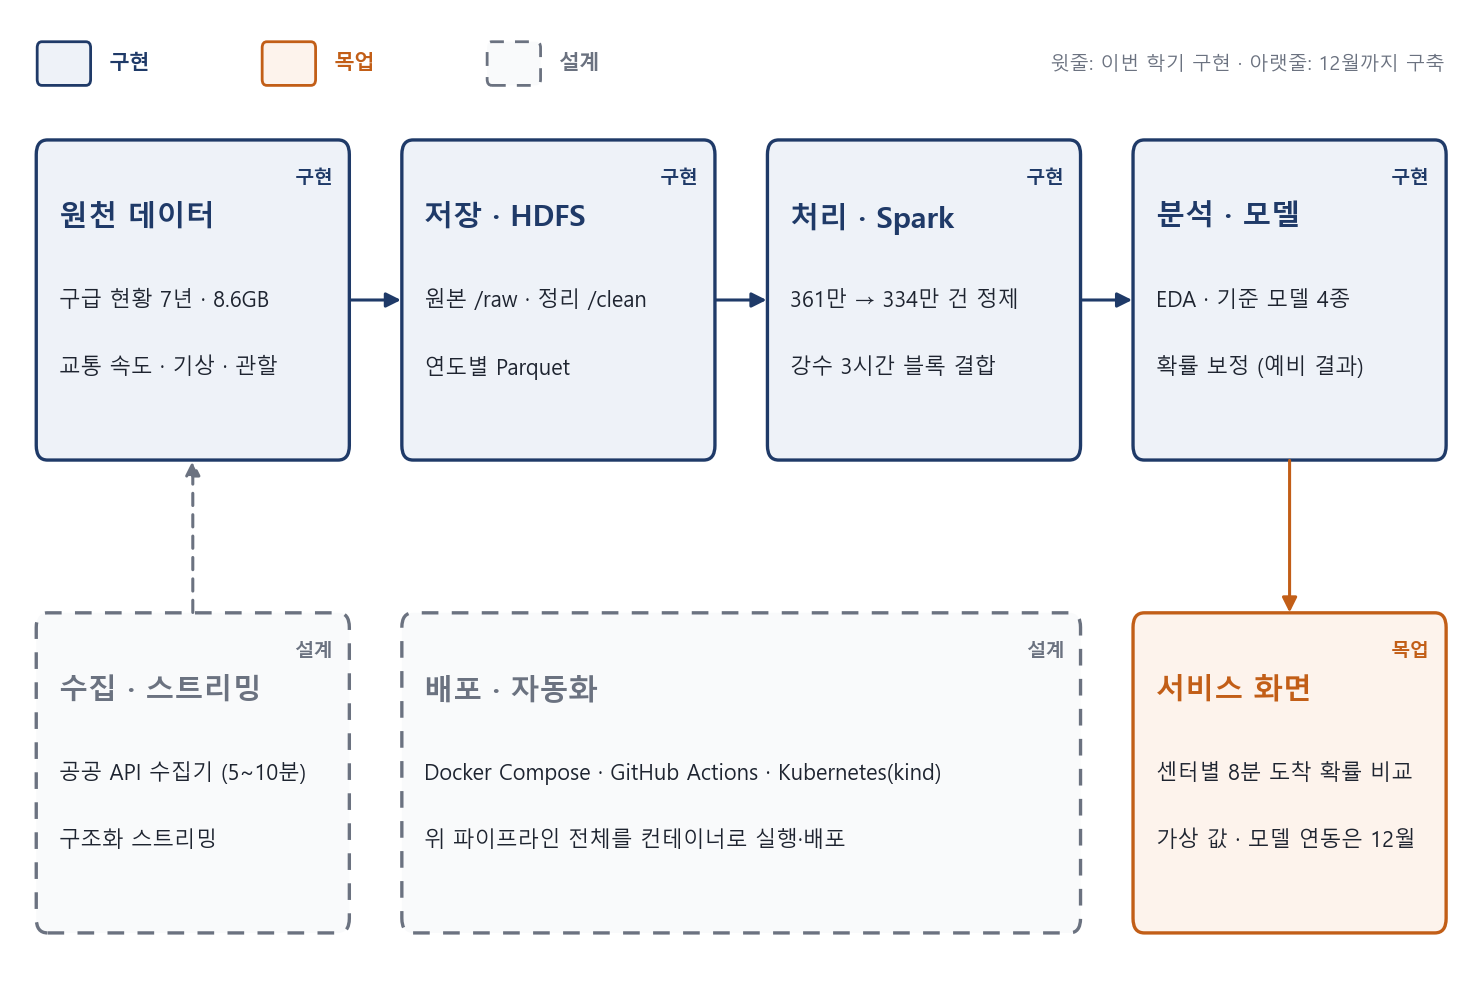

C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project\기업튜터링\발표자료\슬라이드자료\P09_슬8_아키텍처_3x2.png


In [6]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

OUT9 = OUT.with_name("P09_슬8_아키텍처_3x2.png")
STYLE = {
    "구현": dict(ec=NAVY, fc="#EEF2F8", ls="-", tc=NAVY),
    "목업": dict(ec=ORANGE, fc="#FDF3EC", ls="-", tc=ORANGE),
    "설계": dict(ec="#6B7280", fc="#F9FAFB", ls=(0, (5, 4)), tc="#6B7280"),
}
W, H = 3.3, 2.6
boxes = {
    "src": (0.3, 4.3, "원천 데이터", ["구급 현황 7년 · 8.6GB", "교통 속도 · 기상 · 관할"], "구현"),
    "hdfs": (4.2, 4.3, "저장 · HDFS", ["원본 /raw · 정리 /clean", "연도별 Parquet"], "구현"),
    "spark": (8.1, 4.3, "처리 · Spark", ["361만 → 334만 건 정제", "강수 3시간 블록 결합"], "구현"),
    "model": (12.0, 4.3, "분석 · 모델", ["EDA · 기준 모델 4종", "확률 보정 (예비 결과)"], "구현"),
    "collect": (0.3, 0.4, "수집 · 스트리밍", ["공공 API 수집기 (5~10분)", "구조화 스트리밍"], "설계"),
    "deploy": (4.2, 0.4, "배포 · 자동화", ["Docker Compose · GitHub Actions · Kubernetes(kind)", "위 파이프라인 전체를 컨테이너로 실행·배포"], "설계"),
    "service": (12.0, 0.4, "서비스 화면", ["센터별 8분 도착 확률 비교", "가상 값 · 모델 연동은 12월"], "목업"),
}

fig, ax = plt.subplots(figsize=(15, 10))
ax.set_xlim(0, 15.6)
ax.set_ylim(0, 8.0)
ax.axis("off")

for key, (x0, y0, title, lines, status) in boxes.items():
    st = STYLE[status]
    w = (8.1 + W - 4.2) if key == "deploy" else W
    ax.add_patch(FancyBboxPatch((x0, y0), w, H, boxstyle="round,pad=0.02,rounding_size=0.12",
                                ec=st["ec"], fc=st["fc"], lw=2.4, ls=st["ls"]))
    ax.text(x0 + w - 0.15, y0 + H - 0.22, status, ha="right", va="top", fontsize=14, color=st["tc"], fontweight="bold")
    ax.text(x0 + 0.22, y0 + H - 0.62, title, ha="left", va="center", fontsize=21, color=st["tc"], fontweight="bold")
    for i, line in enumerate(lines):
        ax.text(x0 + 0.22, y0 + H - 1.3 - i * 0.55, line, ha="left", va="center", fontsize=15.5, color="#1E2430")

def arrow(p0, p1, color=NAVY, ls="-"):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=22, lw=2.2, color=color, linestyle=ls))

ymid = 4.3 + H / 2
arrow((0.3 + W, ymid), (4.2, ymid))
arrow((4.2 + W, ymid), (8.1, ymid))
arrow((8.1 + W, ymid), (12.0, ymid))
arrow((12.0 + W / 2, 4.3), (12.0 + W / 2, 0.4 + H), color=ORANGE)
arrow((0.3 + W / 2, 0.4 + H), (0.3 + W / 2, 4.3), color="#6B7280", ls=(0, (4, 3)))

lx, ly = 0.3, 7.55
for i, (name, st) in enumerate(STYLE.items()):
    x = lx + i * 2.4
    ax.add_patch(FancyBboxPatch((x, ly - 0.17), 0.55, 0.34, boxstyle="round,pad=0.01,rounding_size=0.05",
                                ec=st["ec"], fc=st["fc"], lw=2, ls=st["ls"]))
    ax.text(x + 0.75, ly, name, va="center", fontsize=15, color=st["tc"], fontweight="bold")
ax.text(15.3, 7.55, "윗줄: 이번 학기 구현 · 아랫줄: 12월까지 구축", ha="right", va="center", fontsize=14, color="#6B7280")

plt.tight_layout()
plt.savefig(OUT9, dpi=200, facecolor="white")
plt.show()
print(OUT9)

## 슬라이드 9 보정 곡선 (발표용)

노트북 06 4절(`04_보정곡선.png`)과 같은 데이터·조건으로 다시 그린다. 학습 2019~2022, 보정 구간 2024(1~12월), 거리 포함 설정, 보정 전(raw)과 보정 후(cross-fit).
약어(LR D+, G0 D+)를 풀어 쓰고 글자를 약 1.5배로 키웠다.

출력: `기업튜터링/발표자료/슬라이드자료/P10_슬9_보정곡선.png`

model  stage   
g0     crossfit    10
       raw         10
lr     crossfit    10
       raw         10
dtype: int64


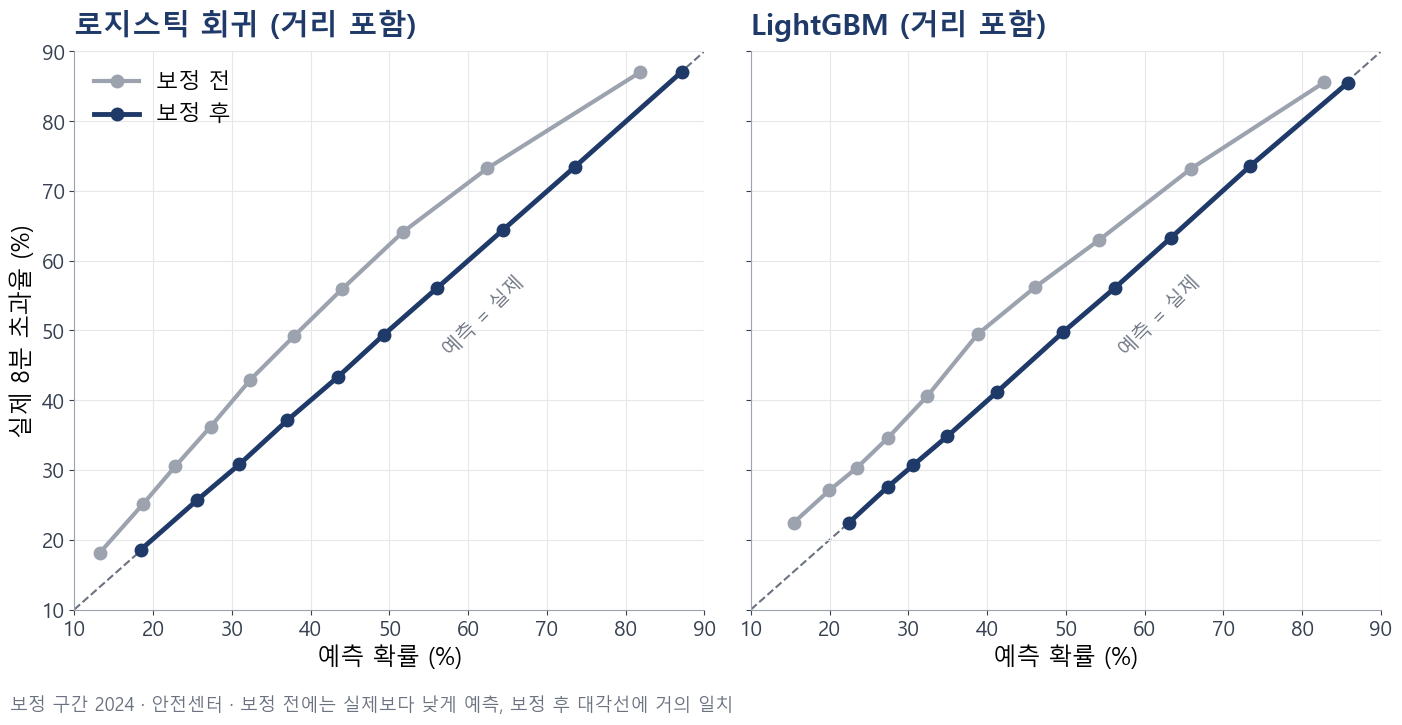

C:\Users\DongHyeok\Desktop\Campus_Life\3-2\Big_Data_Project\기업튜터링\발표자료\슬라이드자료\P10_슬9_보정곡선.png


In [7]:
calib = pd.read_csv(ROOT / "results" / "calibration_midterm.csv")
c = calib[(calib.train_years == "2019-2022") & (calib.calib_months == "1-12") & (calib.split == "calib")
          & (calib.dist == "dplus") & (calib.model.isin(["lr", "g0"]))]
print(c.groupby(["model", "stage"]).size())

OUT10 = OUT.with_name("P10_슬9_보정곡선.png")
fig, axs = plt.subplots(1, 2, figsize=(14, 7.2), sharey=True)
for ax, m, t in zip(axs, ["lr", "g0"], ["로지스틱 회귀 (거리 포함)", "LightGBM (거리 포함)"]):
    ax.plot([10, 90], [10, 90], ls="--", color="#6B7280", lw=1.5, zorder=1)
    for stage, col, lab, lw in [("raw", GRAY, "보정 전", 3), ("crossfit", NAVY, "보정 후", 3.5)]:
        s = c[(c.model == m) & (c.stage == stage)].sort_values("mean_p")
        ax.plot(s.mean_p * 100, s.obs_rate * 100, marker="o", ms=9, lw=lw, color=col, label=lab, zorder=3)
    ax.set_xlim(10, 90)
    ax.set_ylim(10, 90)
    ax.set_title(t, fontsize=21, fontweight="bold", color=NAVY, loc="left", pad=12)
    ax.set_xlabel("예측 확률 (%)", fontsize=17)
    ax.tick_params(labelsize=15, colors="#374151")
    ax.grid(color=LIGHT, lw=0.8)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    for sp in ["left", "bottom"]:
        ax.spines[sp].set_color(GRAY)
    ax.text(62, 52, "예측 = 실제", rotation=45, fontsize=14, color="#6B7280", ha="center", va="center")
axs[0].set_ylabel("실제 8분 초과율 (%)", fontsize=17)
axs[0].legend(fontsize=16, frameon=False, loc="upper left")
fig.text(0.01, 0.005, "보정 구간 2024 · 안전센터 · 보정 전에는 실제보다 낮게 예측, 보정 후 대각선에 거의 일치", fontsize=13, color="#6B7280")
plt.tight_layout(rect=(0, 0.04, 1, 1), w_pad=3)
plt.savefig(OUT10, dpi=200, facecolor="white")
plt.show()
print(OUT10)